In [1]:
import os
import glob
import numpy as np
import scipy.io
import matplotlib.pyplot as plt

from scipy.stats import kurtosis, skew
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils import shuffle


In [2]:
def extract_features(signal, fs=12000, window_size=1024):
    """
    Extracts combined time and frequency domain features
    from vibration signal windows.
    """
    num_windows = len(signal) // window_size
    features = []

    for i in range(num_windows):
        window = signal[i*window_size : (i+1)*window_size]

        # ---- Time Domain ----
        mean_val = np.mean(window)
        std_val = np.std(window)
        rms_val = np.sqrt(np.mean(window**2))
        peak_val = np.max(np.abs(window))
        kurt_val = kurtosis(window)
        skew_val = skew(window)
        crest_factor = peak_val / (rms_val + 1e-6)

        # ---- Frequency Domain (FFT) ----
        fft_vals = np.abs(np.fft.rfft(window))
        fft_freqs = np.fft.rfftfreq(window_size, 1/fs)

        peak_freq = fft_freqs[np.argmax(fft_vals)]
        spec_centroid = np.sum(fft_freqs * fft_vals) / (np.sum(fft_vals) + 1e-6)

        features.append([
            mean_val, std_val, rms_val,
            kurt_val, skew_val, crest_factor,
            peak_freq, spec_centroid
        ])

    return np.array(features)


In [11]:
def load_labeled_data(dataset_path):
    """
    Loads labeled data with leakage-free splitting.
    Train: First 80% of each signal
    Test : Last 20% of each signal
    """
    X_train, y_train = [], []
    X_test, y_test = [], []

    label_map = {
        "Normal": 0,
        "B": 1,
        "IR": 2,
        "OR": 3
    }

    files = glob.glob(os.path.join(dataset_path, "**", "*.mat"), recursive=True)
    print(f"Found {len(files)} files for processing...")

    for filepath in files:
        try:
            filename = os.path.basename(filepath)

            label = None
            if "Normal" in filepath:
                label = 0
            elif os.sep + "B" + os.sep in filepath:
                label = 1
            elif os.sep + "IR" + os.sep in filepath:
                label = 2
            elif os.sep + "OR" + os.sep in filepath:
                label = 3
            else:
                continue
           

            mat = scipy.io.loadmat(filepath)
            de_key = next((k for k in mat.keys() if "DE_time" in k), None)
            if de_key is None:
                continue

            signal = mat[de_key].flatten()

            split_idx = int(0.8 * len(signal))
            train_sig = signal[:split_idx]
            test_sig = signal[split_idx:]

            train_feats = extract_features(train_sig)
            test_feats = extract_features(test_sig)

            if len(train_feats) > 0:
                X_train.append(train_feats)
                y_train.extend([label] * len(train_feats))

            if len(test_feats) > 0:
                X_test.append(test_feats)
                y_test.extend([label] * len(test_feats))

        except Exception as e:
            print(f"Error processing {filepath}: {e}")

    return (
        np.vstack(X_train), np.array(y_train),
        np.vstack(X_test), np.array(y_test)
    )


In [15]:
dataset_path = r"./CWRU-dataset"

X_train, y_train, X_test, y_test = load_labeled_data(dataset_path)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape :", X_test.shape)


Found 161 files for processing...
Training Data Shape: (28038, 8)
Testing Data Shape : (6923, 8)


In [16]:
X_train, y_train = shuffle(X_train, y_train, random_state=42)


In [17]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [18]:
clf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

clf.fit(X_train_scaled, y_train)


RandomForestClassifier(n_jobs=-1, random_state=42)

In [19]:
labels = [0, 1, 2, 3]
target_names = ["Normal", "Ball Fault", "Inner Race Fault", "Outer Race Fault"]

y_pred = clf.predict(X_test_scaled)

print("=== Classification Report ===\n")
print(
    classification_report(
        y_test,
        y_pred,
        labels=labels,
        target_names=target_names,
        zero_division=0
    )
)


=== Classification Report ===

                  precision    recall  f1-score   support

          Normal       1.00      0.99      1.00       329
      Ball Fault       0.87      0.84      0.85      1640
Inner Race Fault       0.95      0.93      0.94      1601
Outer Race Fault       0.92      0.95      0.93      3353

        accuracy                           0.92      6923
       macro avg       0.94      0.93      0.93      6923
    weighted avg       0.92      0.92      0.92      6923



In [20]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:\n")
print(cm)


Confusion Matrix:

[[ 327    2    0    0]
 [   0 1378   37  225]
 [   0   61 1493   47]
 [   0  143   36 3174]]


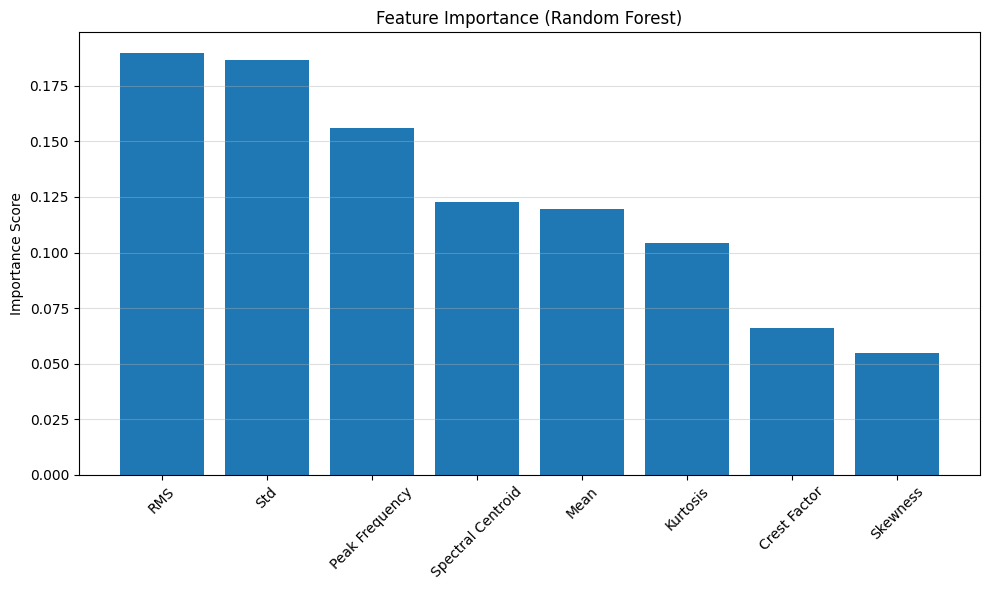

In [21]:
feature_names = [
    "Mean", "Std", "RMS",
    "Kurtosis", "Skewness", "Crest Factor",
    "Peak Frequency", "Spectral Centroid"
]

importances = clf.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10,6))
plt.title("Feature Importance (Random Forest)")
plt.bar(range(len(importances)), importances[indices])
plt.xticks(range(len(importances)), [feature_names[i] for i in indices], rotation=45)
plt.ylabel("Importance Score")
plt.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()


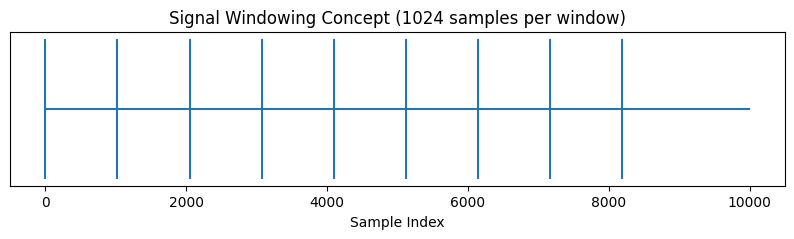

In [22]:
signal_length = 10000
window_size = 1024

num_windows = signal_length // window_size

plt.figure(figsize=(10,2))
plt.hlines(1, 0, signal_length)
for i in range(num_windows):
    plt.vlines(i*window_size, 0.95, 1.05)

plt.title("Signal Windowing Concept (1024 samples per window)")
plt.xlabel("Sample Index")
plt.yticks([])
plt.show()


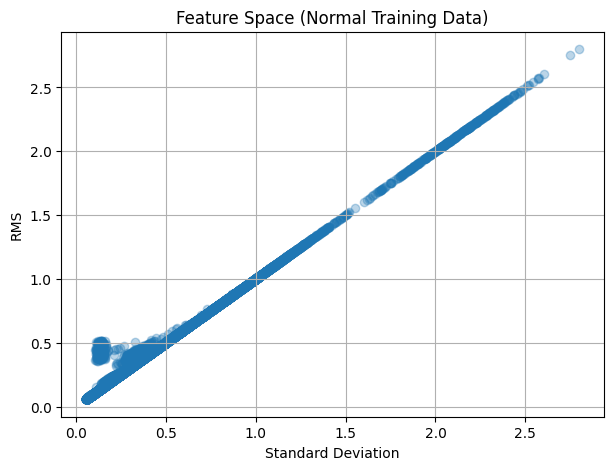

In [23]:
plt.figure(figsize=(7,5))
plt.scatter(X_train[:,1], X_train[:,2], alpha=0.3)
plt.xlabel("Standard Deviation")
plt.ylabel("RMS")
plt.title("Feature Space (Normal Training Data)")
plt.grid(True)
plt.show()


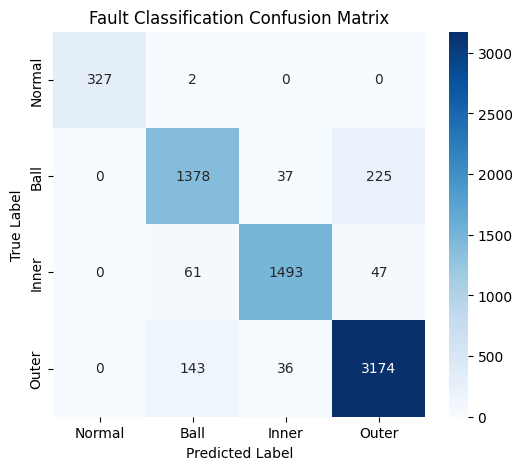

In [25]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Ball", "Inner", "Outer"],
    yticklabels=["Normal", "Ball", "Inner", "Outer"]
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Fault Classification Confusion Matrix")
plt.show()


## END-TO-END SUMMARY:

1. Raw vibration signals are segmented into windows
2. Time + frequency features are extracted
3. Normal data trains One-Class SVM (anomaly detector)
4. Unseen data is evaluated for anomalies
5. Detected anomalies are classified using Random Forest
6. Model performance is evaluated using:
   - Classification Report
   - Confusion Matrix
   - Feature Importance